# Day 03 | Pandas: Read and Clean Tables

**KGP Talkie | Day 03**

We use Python dictionaries, lists, and indexing. All data is made inside this notebook. If pandas is missing, run `%pip install pandas` in a new cell, then restart the kernel.

Run the cells in order. Each new term is explained before we use it.

## Learning path

1. What is pandas?
2. Rows, columns, cells, and the index
3. Creating a DataFrame
4. Series versus DataFrame
5. Inspecting a DataFrame
6. Index labels and set_index()
7. Selecting with loc and iloc
8. Boolean filtering
9. Sorting rows
10. Creating and updating columns
11. Missing values: detection
12. Missing values: fillna and dropna
13. Duplicate rows
14. Text cleaning and type conversion
15. Counting categories
16. GroupBy and aggregation
17. Renaming and removing columns
18. Combining tables with merge()
19. CSV files: saving and reading
20. Preparing a small table for AI
21. Practice

## 1. What is pandas?

**pandas** is a Python library for working with tables. We use it to read data, select rows, change columns, handle missing values, and calculate summaries.

A **dataset** is a collection of related data. Our dataset describes eight students. These are invented practice records, not results from a real study.

In [1]:
import pandas as pd  # pd is the common alias for pandas.

## 2. Rows, columns, cells, and the index

A **row** holds one record, such as one student. A **column** holds one kind of information, such as scores. A **cell** holds a value at the meeting of a row and column. The **index** contains row labels.

A **DataFrame** is a two-dimensional table with rows and columns. Columns can have different types: names can be text while scores are numbers.

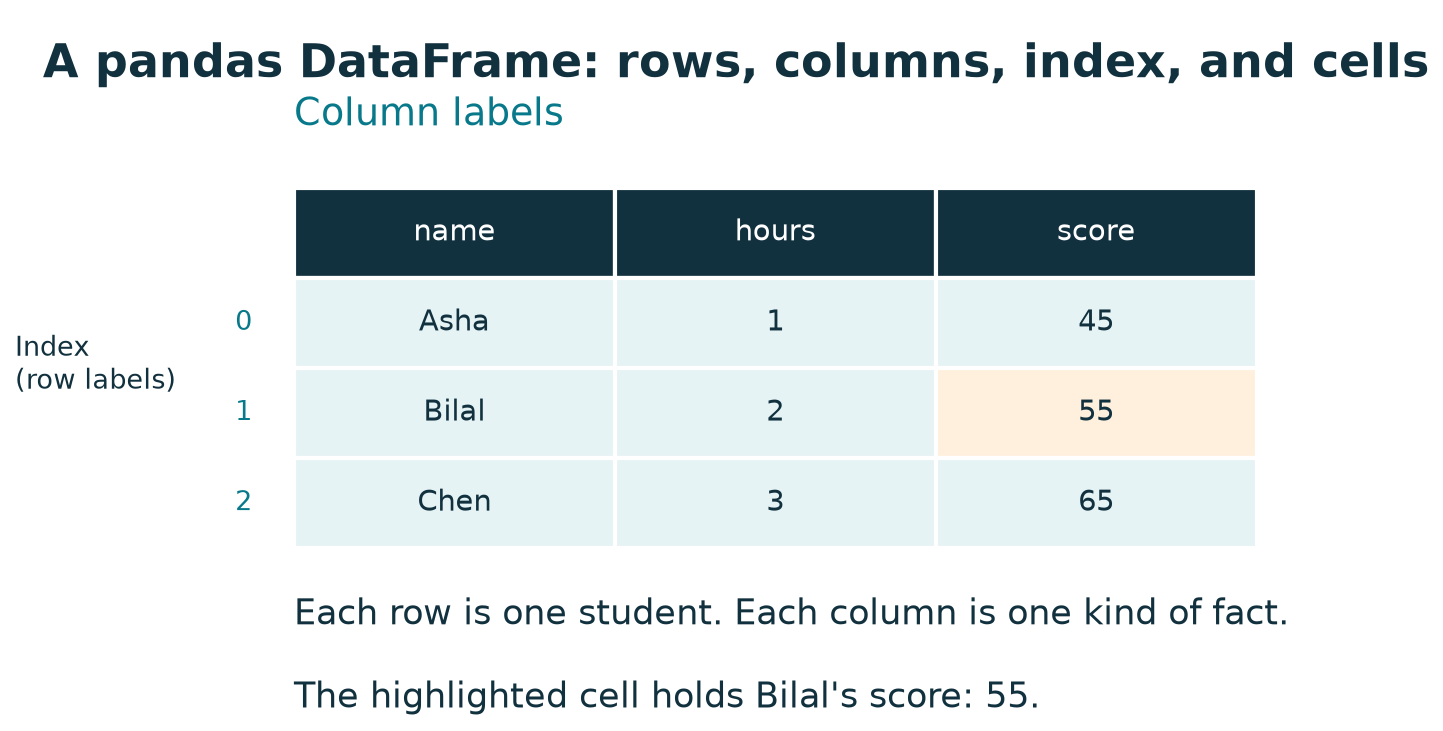

The index labels the rows. Column labels describe the kind of information in each column.

## 3. Creating a DataFrame

`pd.DataFrame()` constructs a table. We give it a dictionary whose keys become column names and whose lists become column values. The lists must have equal lengths here.

| Column | Meaning |
|---|---|
| `student_id` | A unique label for a student |
| `name` | Student name |
| `group` | Class group A or B |
| `hours` | Study hours for this example |
| `practice` | Number of practice questions completed |
| `score` | Score out of 100; one score is missing |

`None` marks a missing score in our input data.

In [2]:
students = pd.DataFrame({
    'student_id': [101, 102, 103, 104, 105, 106, 107, 108],
    'name': ['Asha', 'Bilal', 'Chen', 'Diya', 'Eshan', 'Fatima', 'Gita', 'Hari'],
    'group': ['A', 'B', 'A', 'B', 'A', 'B', 'A', 'B'],
    'hours': [1, 2, 3, 4, 2, 5, 3, 4],
    'practice': [2, 4, 5, 7, 3, 8, 6, 6],
    'score': [45, 55, 65, 78, 52, 90, None, 74]
})

In [3]:
students  # Display the complete small table.

,student_id,name,group,hours,practice,score
0,101,Asha,A,1,2,45.0
1,102,Bilal,B,2,4,55.0
2,103,Chen,A,3,5,65.0
3,104,Diya,B,4,7,78.0
4,105,Eshan,A,2,3,52.0
5,106,Fatima,B,5,8,90.0
6,107,Gita,A,3,6,NaN
7,108,Hari,B,4,6,74.0


The leftmost numbers 0 to 7 are the default index. They are row labels, not a column from our dictionary. `NaN` in the score column marks a missing number.

## 4. Series versus DataFrame

A **Series** is a one-dimensional labeled collection. Selecting one column with single brackets returns a Series. Selecting a list of columns returns a DataFrame, even when that list has one name.

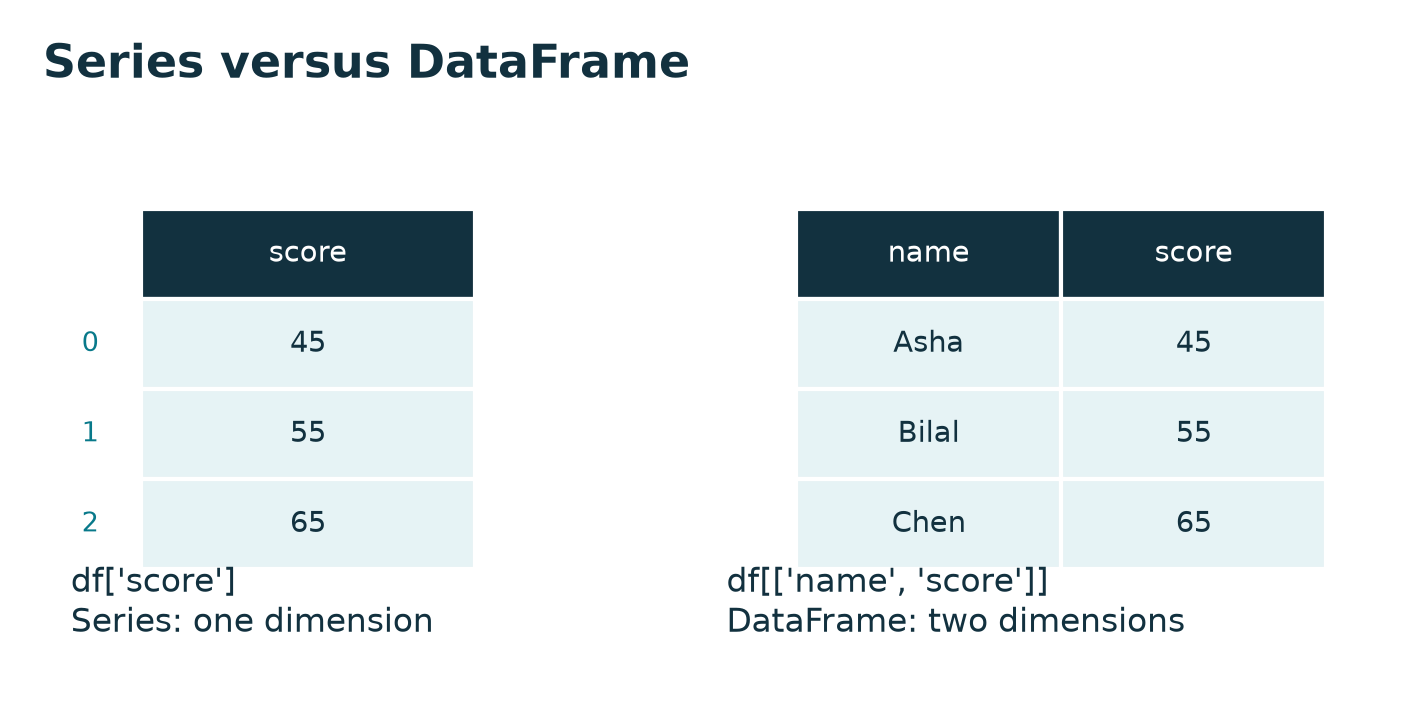

Single brackets around one column name select a Series. A list of names selects a DataFrame.

In [4]:
students['score']

0    45.0
1    55.0
2    65.0
3    78.0
4    52.0
5    90.0
6     NaN
7    74.0
Name: score, dtype: float64

In [5]:
type(students['score'])

pandas.core.series.Series

In [6]:
students[['score']]  # A one-column DataFrame.

,score
0,45.0
1,55.0
2,65.0
3,78.0
4,52.0
5,90.0
6,NaN
7,74.0


In [7]:
type(students[['score']])

pandas.core.frame.DataFrame

In [8]:
students[['name', 'hours', 'score']]  # Three selected columns.

,name,hours,score
0,Asha,1,45.0
1,Bilal,2,55.0
2,Chen,3,65.0
3,Diya,4,78.0
4,Eshan,2,52.0
5,Fatima,5,90.0
6,Gita,3,NaN
7,Hari,4,74.0


## 5. Inspecting a DataFrame

**Inspection** means checking the table before changing or analysing it. `head(n)` displays the first `n` rows; `tail(n)` displays the last `n`. The default is five.

`shape`, `columns`, and `dtypes` are **attributes**, so they have no parentheses. `head()` and `info()` are **methods**, so they have parentheses.

In [9]:
students.head(3)

,student_id,name,group,hours,practice,score
0,101,Asha,A,1,2,45.0
1,102,Bilal,B,2,4,55.0
2,103,Chen,A,3,5,65.0


In [10]:
students.tail(2)

,student_id,name,group,hours,practice,score
6,107,Gita,A,3,6,NaN
7,108,Hari,B,4,6,74.0


In [11]:
students.shape  # (number of rows, number of columns).

(8, 6)

In [12]:
students.columns

Index(['student_id', 'name', 'group', 'hours', 'practice', 'score'], dtype='object')

In [13]:
students.dtypes

student_id      int64
name           object
group          object
hours           int64
practice        int64
score         float64
dtype: object

The missing value makes our score column use a type that can hold a missing number. Text columns may appear as `object` or a string dtype, depending on the pandas version. In this output, `object` is a column dtype; it does not mean that the column contains only one value.

In [14]:
students.info()  # Column types and counts of non-missing values.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  8 non-null      int64  
 1   name        8 non-null      object 
 2   group       8 non-null      object 
 3   hours       8 non-null      int64  
 4   practice    8 non-null      int64  
 5   score       7 non-null      float64
dtypes: float64(1), int64(3), object(2)
memory usage: 516.0+ bytes


`info()` prints a summary and returns `None`. The score column has seven non-missing values, while the other columns have eight. `describe()` gives summary statistics for numeric columns.

In [15]:
students[['hours', 'practice', 'score']].describe()

,hours,practice,score
count,8.000000,8.00000,7.000000
mean,3.000000,5.12500,65.571429
std,1.309307,2.03101,16.029734
min,1.000000,2.00000,45.000000
25%,2.000000,3.75000,53.500000
50%,3.000000,5.50000,65.000000
75%,4.000000,6.25000,76.000000
max,5.000000,8.00000,90.000000


In `describe()`, `count` excludes missing values. `mean` is the average. `std` is sample standard deviation. `25%`, `50%`, and `75%` are quartiles; `50%` is the median. `min` and `max` give the range endpoints.

## 6. Index labels and set_index()

A **row label** identifies a row. A **row position** is where the row sits, starting at 0. They can be different.

`set_index()` returns a DataFrame with a chosen column used as its index. We keep a separate table called `by_id` so the original table keeps its default index.

In [16]:
by_id = students.set_index('student_id')

In [17]:
by_id.head(3)

,name,group,hours,practice,score
student_id,,,,,
101,Asha,A,1,2,45.0
102,Bilal,B,2,4,55.0
103,Chen,A,3,5,65.0


## 7. Selecting with loc and iloc

`loc` selects by **labels**. `iloc` selects by **integer positions**. Both use square brackets because they are indexers.

| Expression | Meaning |
|---|---|
| `by_id.loc[102, "score"]` | Row label 102, column label score |
| `by_id.iloc[1, 4]` | Second row, fifth column |

After making `student_id` the index, the columns of `by_id` are name, group, hours, practice, and score.

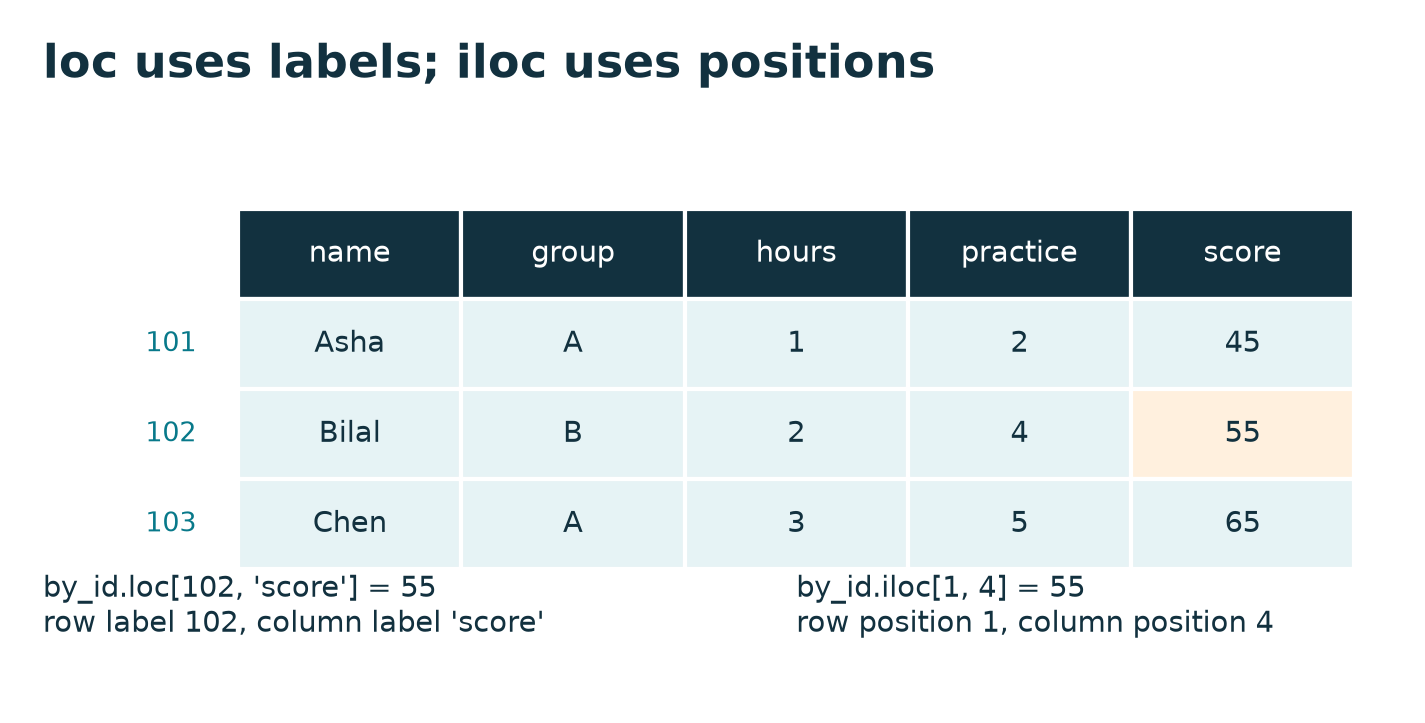

Both expressions select Bilal's score. The row label is 102, but its position is 1. The score column is at position 4.

In [18]:
by_id.loc[102, 'score']

np.float64(55.0)

In [19]:
by_id.iloc[1, 4]

np.float64(55.0)

In [20]:
by_id.loc[101:103, ['name', 'score']]  # Label slices include the stop label.

,name,score
student_id,,
101,Asha,45.0
102,Bilal,55.0
103,Chen,65.0


In [21]:
by_id.iloc[0:3, 0:2]  # Position slices exclude the stop position.

,name,group
student_id,,
101,Asha,A
102,Bilal,B
103,Chen,A


## 8. Boolean filtering

**Filtering** selects rows that satisfy a condition. First, the comparison returns a Boolean Series. Then we use that Series as a mask inside `[]`.

We want students whose study hours are at least 3.

In [22]:
mask = students['hours'] >= 3

In [23]:
mask  # One True or False value per row.

0    False
1    False
2     True
3     True
4    False
5     True
6     True
7     True
Name: hours, dtype: bool

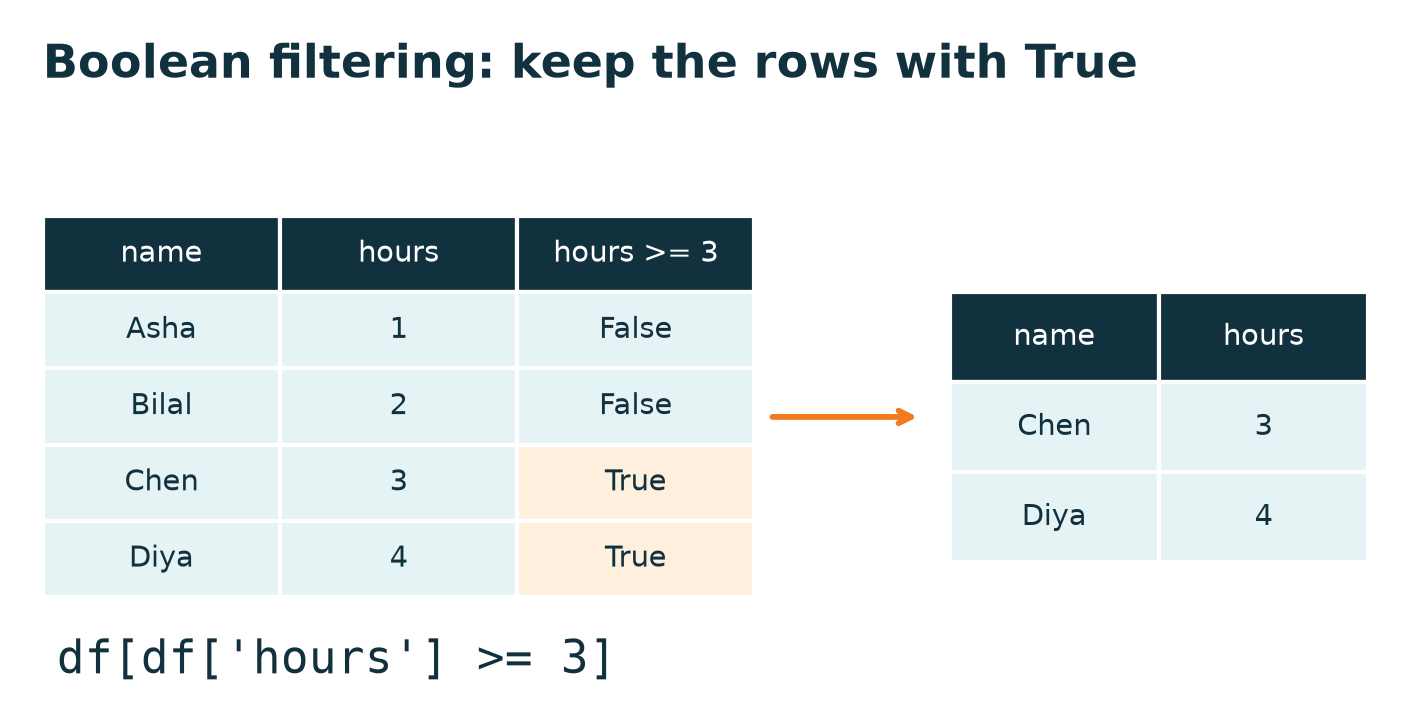

Rows with True are kept. Their original index labels stay with them.

In [24]:
students[mask]

,student_id,name,group,hours,practice,score
2,103,Chen,A,3,5,65.0
3,104,Diya,B,4,7,78.0
5,106,Fatima,B,5,8,90.0
6,107,Gita,A,3,6,NaN
7,108,Hari,B,4,6,74.0


We can write the comparison directly inside the brackets when we no longer need a separate mask.

In [25]:
students[students['hours'] >= 3]

,student_id,name,group,hours,practice,score
2,103,Chen,A,3,5,65.0
3,104,Diya,B,4,7,78.0
5,106,Fatima,B,5,8,90.0
6,107,Gita,A,3,6,NaN
7,108,Hari,B,4,6,74.0


With pandas conditions, use `&` for and, `|` for or, and `~` for not. Put each comparison in parentheses. Python's `and` and `or` do not combine whole Series element by element.

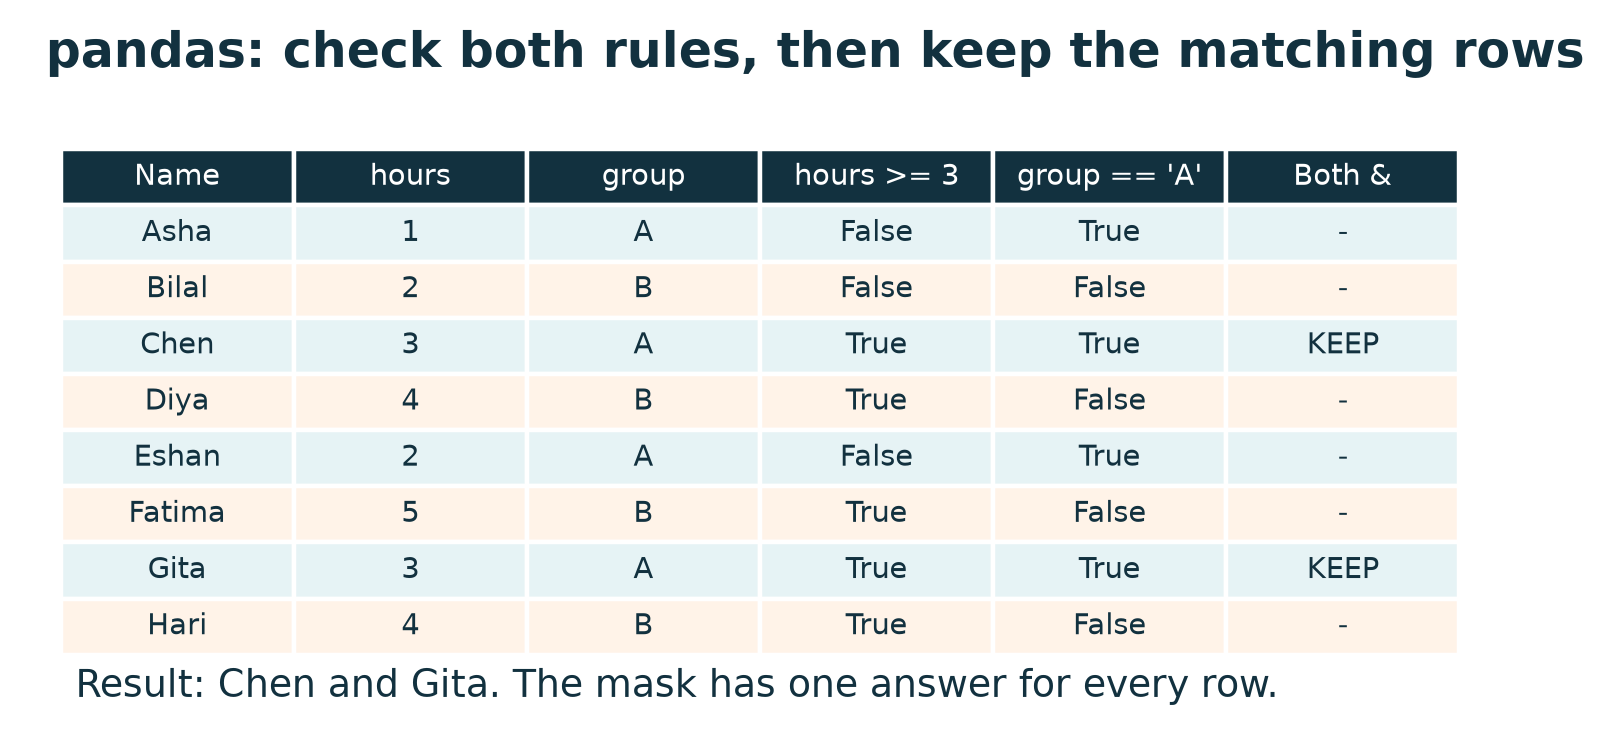

Chen and Gita meet both rules. Diya, Fatima, and Hari meet the hours rule but are not in group A.

In [26]:
hours_mask = students['hours'] >= 3  # Check each student's hours.

In [27]:
group_mask = students['group'] == 'A'  # Check each student's group.

In [28]:
both_mask = hours_mask & group_mask  # Both answers must be True for a row.

In [29]:
both_mask  # Each index still refers to the same student row.

0    False
1    False
2     True
3    False
4    False
5    False
6     True
7    False
dtype: bool

In [30]:
students[both_mask]  # Keep Chen and Gita; drop the False rows.

,student_id,name,group,hours,practice,score
2,103,Chen,A,3,5,65.0
6,107,Gita,A,3,6,NaN


The `isin()` method checks whether each value is in a list of allowed values.

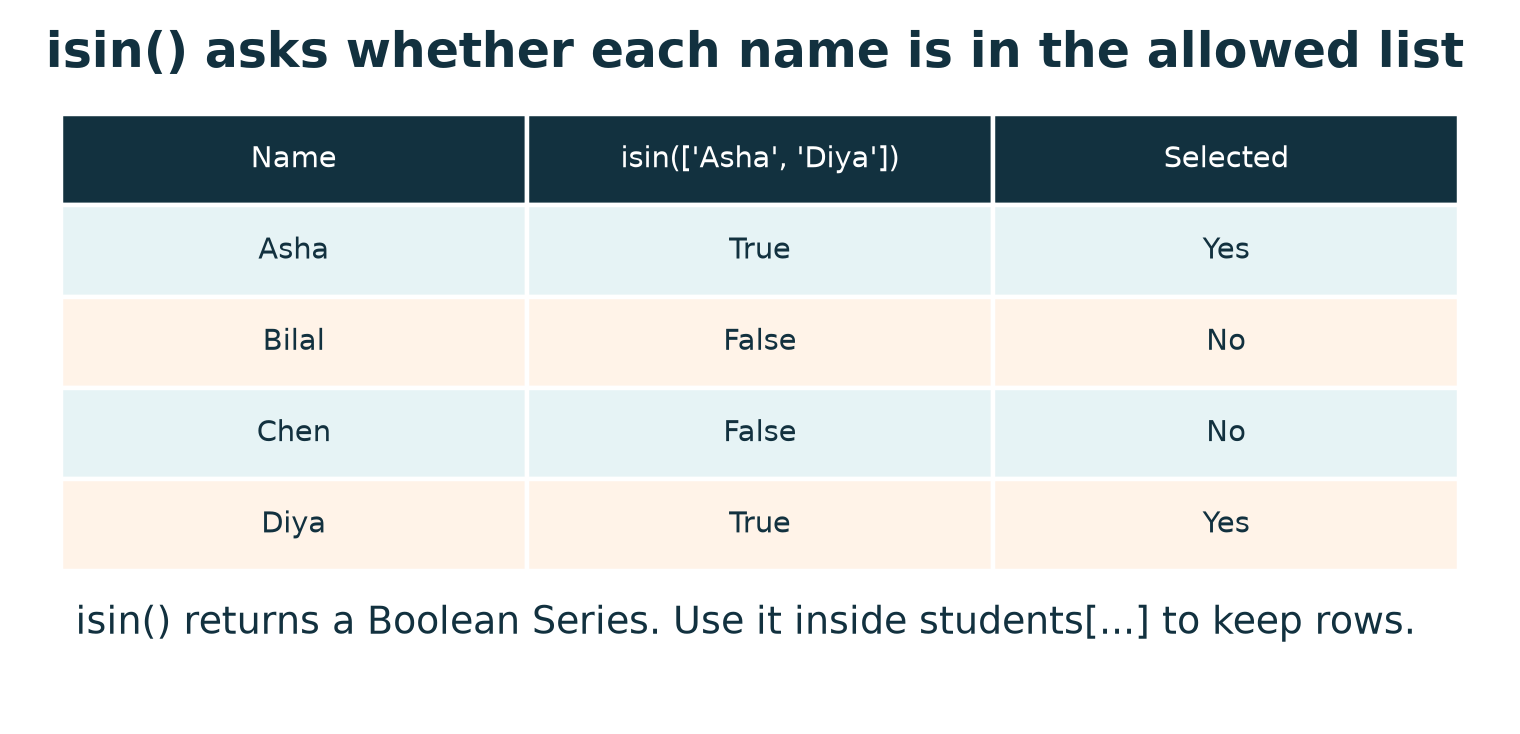

Asha and Diya appear in the allowed list, so their mask values are True.

In [31]:
# isin() checks whether each name appears in the allowed list.
# The outer students[...] keeps the rows where that answer is True.
students[students['name'].isin(['Asha', 'Diya'])]

,student_id,name,group,hours,practice,score
0,101,Asha,A,1,2,45.0
3,104,Diya,B,4,7,78.0


## 9. Sorting rows

`sort_values()` sorts rows using one or more columns. By default it uses **ascending order**, from small to large. `ascending=False` means **descending order**, from large to small. The method returns a new table unless we store or apply the result.

In [32]:
students.sort_values('hours')

,student_id,name,group,hours,practice,score
0,101,Asha,A,1,2,45.0
1,102,Bilal,B,2,4,55.0
4,105,Eshan,A,2,3,52.0
2,103,Chen,A,3,5,65.0
6,107,Gita,A,3,6,NaN
3,104,Diya,B,4,7,78.0
7,108,Hari,B,4,6,74.0
5,106,Fatima,B,5,8,90.0


In [33]:
students.sort_values('score', ascending=False)  # Missing scores appear last by default.

,student_id,name,group,hours,practice,score
5,106,Fatima,B,5,8,90.0
3,104,Diya,B,4,7,78.0
7,108,Hari,B,4,6,74.0
2,103,Chen,A,3,5,65.0
1,102,Bilal,B,2,4,55.0
4,105,Eshan,A,2,3,52.0
0,101,Asha,A,1,2,45.0
6,107,Gita,A,3,6,NaN


## 10. Creating and updating columns

A **derived column** is calculated from existing values. We create a new column by assigning to a new column name. pandas applies the calculation to each row.

We convert study hours to minutes by multiplying by 60, because one hour contains 60 minutes.

In [34]:
students['study_minutes'] = students['hours'] * 60

In [35]:
students[['name', 'hours', 'study_minutes']]

,name,hours,study_minutes
0,Asha,1,60
1,Bilal,2,120
2,Chen,3,180
3,Diya,4,240
4,Eshan,2,120
5,Fatima,5,300
6,Gita,3,180
7,Hari,4,240


To update a specific cell, use one `loc` operation on the original DataFrame. We make a copy first so the original practice data stays available.

In [36]:
edited = students.copy()

In [37]:
edited.loc[0, 'hours'] = 2  # Update row label 0.

In [38]:
edited.loc[0, ['name', 'hours']]

name     Asha
hours       2
Name: 0, dtype: object

Changing hours does not automatically recalculate study_minutes. A derived column is stored data, not a live spreadsheet formula. Recalculate it after updating its source column.

## 11. Missing values: detection

A **missing value** means a value is not available. pandas can display missing data as `NaN`, `None`, or `pd.NA`, depending on the column type. Missing is different from zero: a missing score does not tell us that the student scored 0.

`isna()` returns True for missing cells. Summing the True values counts them.

In [39]:
students.isna()

,student_id,name,group,hours,practice,score,study_minutes
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False
6,False,False,False,False,False,True,False
7,False,False,False,False,False,False,False


In [40]:
students.isna().sum()

student_id       0
name             0
group            0
hours            0
practice         0
score            1
study_minutes    0
dtype: int64

In [41]:
students[students['score'].isna()]  # Show the row with the missing score.

,student_id,name,group,hours,practice,score,study_minutes
6,107,Gita,A,3,6,NaN,180


## 12. Missing values: fillna and dropna

`fillna(value)` replaces missing values. `dropna()` removes rows with missing values by default. The right choice depends on why the data is missing.

For this calculation exercise, we make a new column filled with the mean of known scores. We keep the original column so the made-up value can be identified. A filled mean is not a real test score.

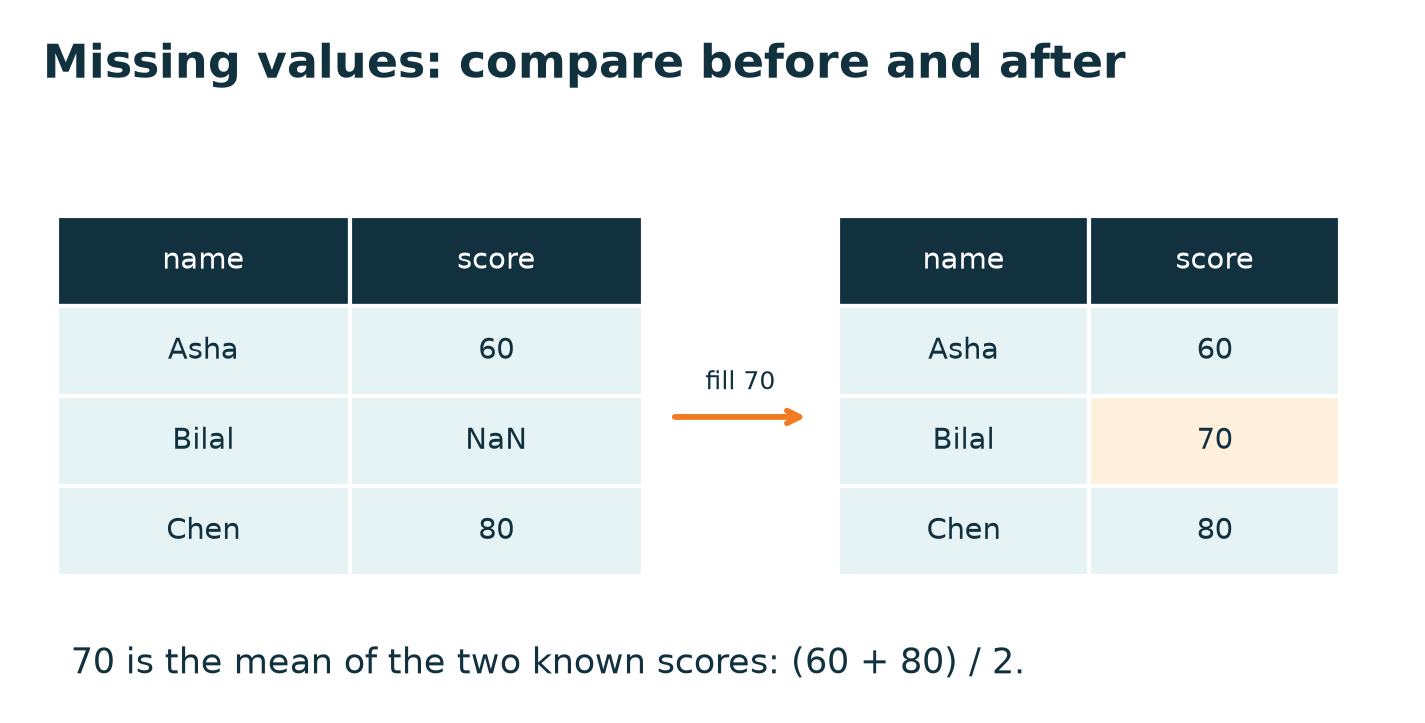

In this separate three-student example, the known scores 60 and 80 have mean 70.

In [42]:
mean_score = students['score'].mean()  # Missing values are skipped by default.

In [43]:
mean_score

np.float64(65.57142857142857)

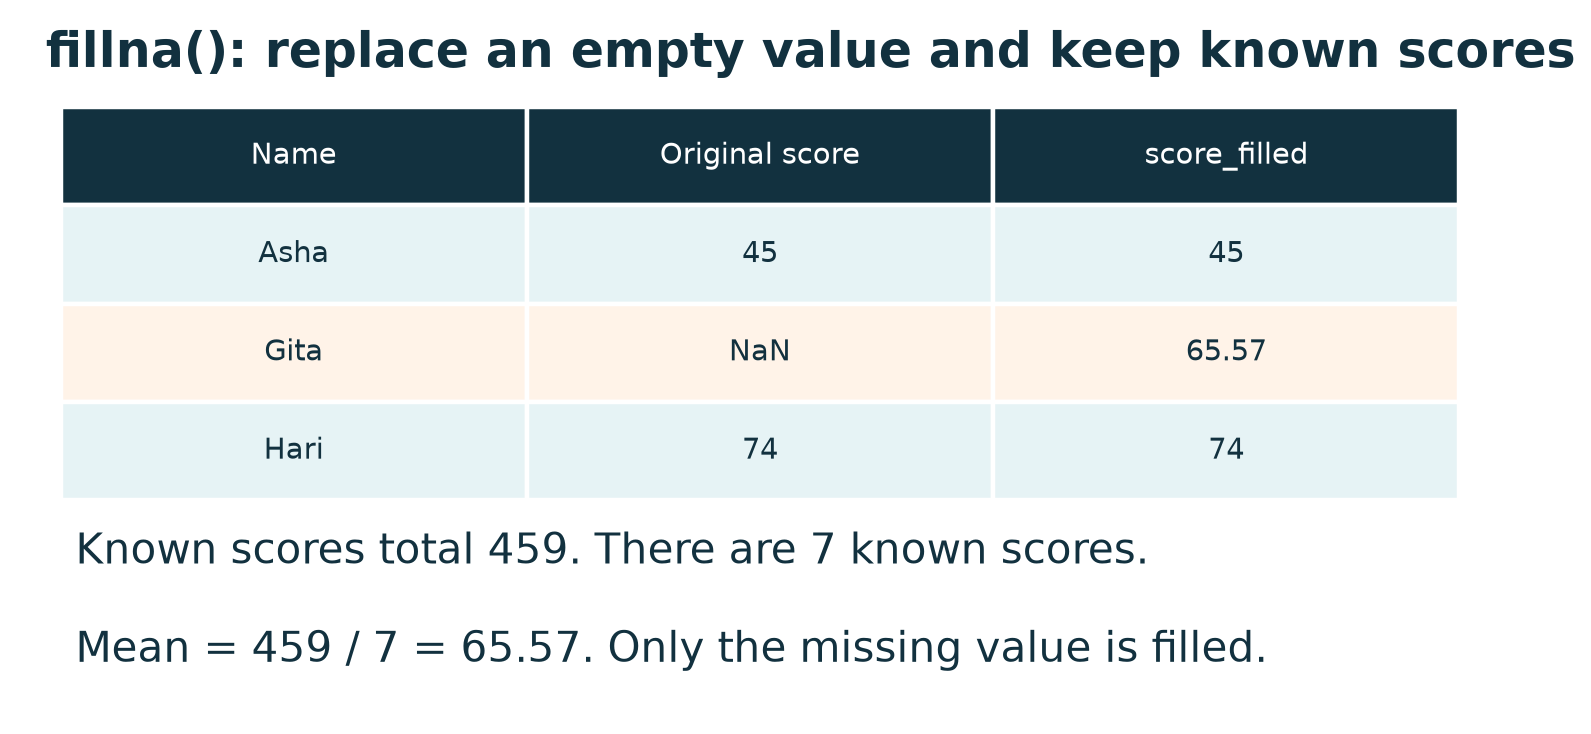

fillna(mean_score) fills only missing scores. The original score column stays available for comparison.

In [44]:
# fillna() changes only missing values. Write into a new column to keep the original.
students['score_filled'] = students['score'].fillna(mean_score)

In [45]:
students[['name', 'score', 'score_filled']]

,name,score,score_filled
0,Asha,45.0,45.000000
1,Bilal,55.0,55.000000
2,Chen,65.0,65.000000
3,Diya,78.0,78.000000
4,Eshan,52.0,52.000000
5,Fatima,90.0,90.000000
6,Gita,NaN,65.571429
7,Hari,74.0,74.000000


Use `subset` to say which column must be present. This returns a seven-row table and leaves students unchanged.

In [46]:
students.dropna(subset=['score'])

,student_id,name,group,hours,practice,score,study_minutes,score_filled
0,101,Asha,A,1,2,45.0,60,45.0
1,102,Bilal,B,2,4,55.0,120,55.0
2,103,Chen,A,3,5,65.0,180,65.0
3,104,Diya,B,4,7,78.0,240,78.0
4,105,Eshan,A,2,3,52.0,120,52.0
5,106,Fatima,B,5,8,90.0,300,90.0
7,108,Hari,B,4,6,74.0,240,74.0


## 13. Duplicate rows

A **duplicate** repeats a row that is already present. `duplicated()` marks repeated rows after the first. `drop_duplicates()` removes them from the returned result.

`pd.concat()` joins tables. We use it here to add a repeated first row for practice. `ignore_index=True` makes fresh index labels.

In [47]:
with_repeat = pd.concat([students, students.iloc[[0]]], ignore_index=True)

In [48]:
with_repeat.duplicated()

0    False
1    False
2    False
3    False
4    False
5    False
6    False
7    False
8     True
dtype: bool

In [49]:
with_repeat.drop_duplicates().shape  # Back to eight unique rows.

(8, 8)

## 14. Text cleaning and type conversion

Text data may contain extra spaces or mixed letter cases. The **string accessor** `.str` applies string methods to a Series. `astype()` converts a column to another dtype when its values allow that change.

In [50]:
raw_names = pd.Series([' Asha ', 'BILAL', ' chen'])

In [51]:
raw_names.str.strip()  # Remove outer spaces in every row.

0     Asha
1    BILAL
2     chen
dtype: object

In [52]:
raw_names.str.strip().str.title()  # Capitalise each name consistently.

0     Asha
1    Bilal
2     Chen
dtype: object

In [53]:
pd.Series(['1', '2', '3']).astype(int)  # Convert whole-number text.

0    1
1    2
2    3
dtype: int64

## 15. Counting categories

A **category** is a label, such as group A or B. `value_counts()` counts rows for each distinct value. `unique()` lists distinct values; `nunique()` counts them. Missing values are excluded by default in these counts.

In [54]:
students['group'].value_counts()

group
A    4
B    4
Name: count, dtype: int64

In [55]:
students['group'].unique()

array(['A', 'B'], dtype=object)

In [56]:
students['group'].nunique()

2

## 16. GroupBy and aggregation

**Grouping** splits records by a shared key. **Aggregation** calculates a summary such as a mean or count. `groupby()` lets us split, calculate, and combine.

We group by the class label, select a number column, and calculate one mean for each group.

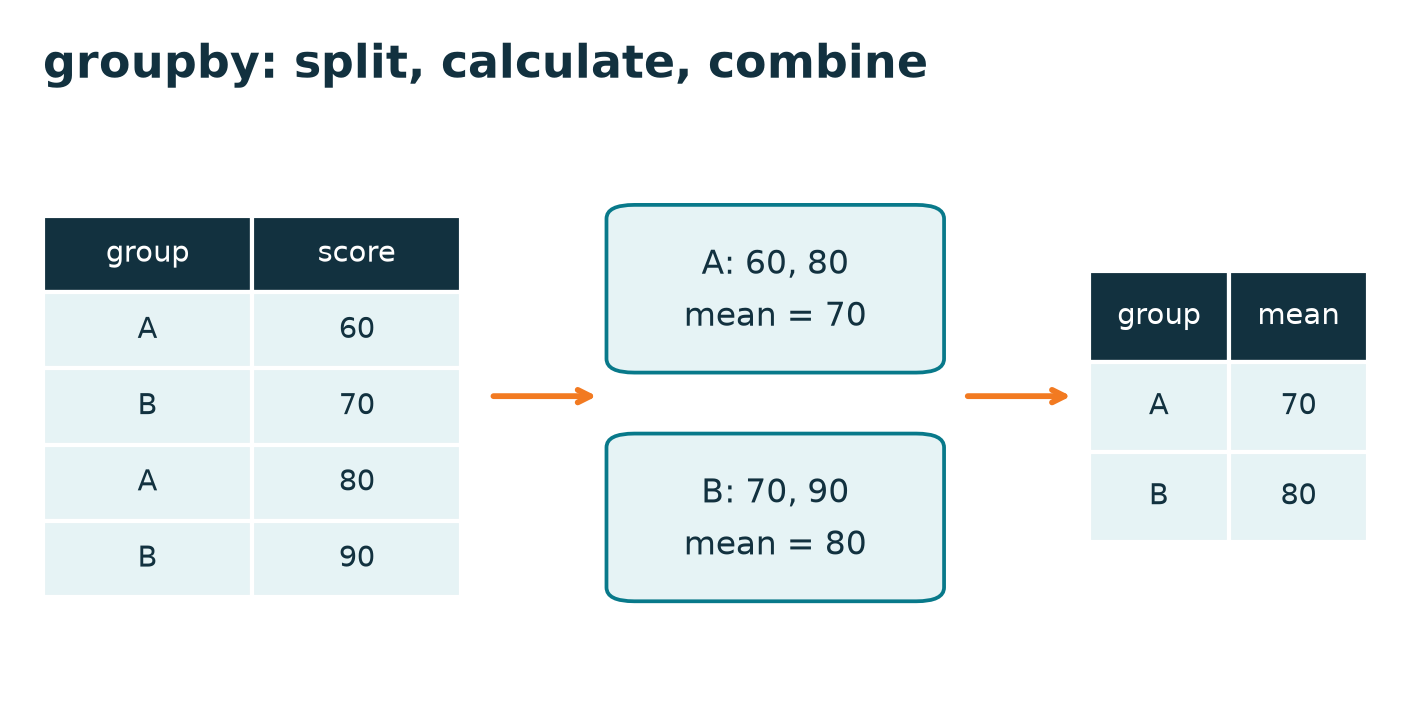

The diagram uses four simple scores. A gets mean 70; B gets mean 80.

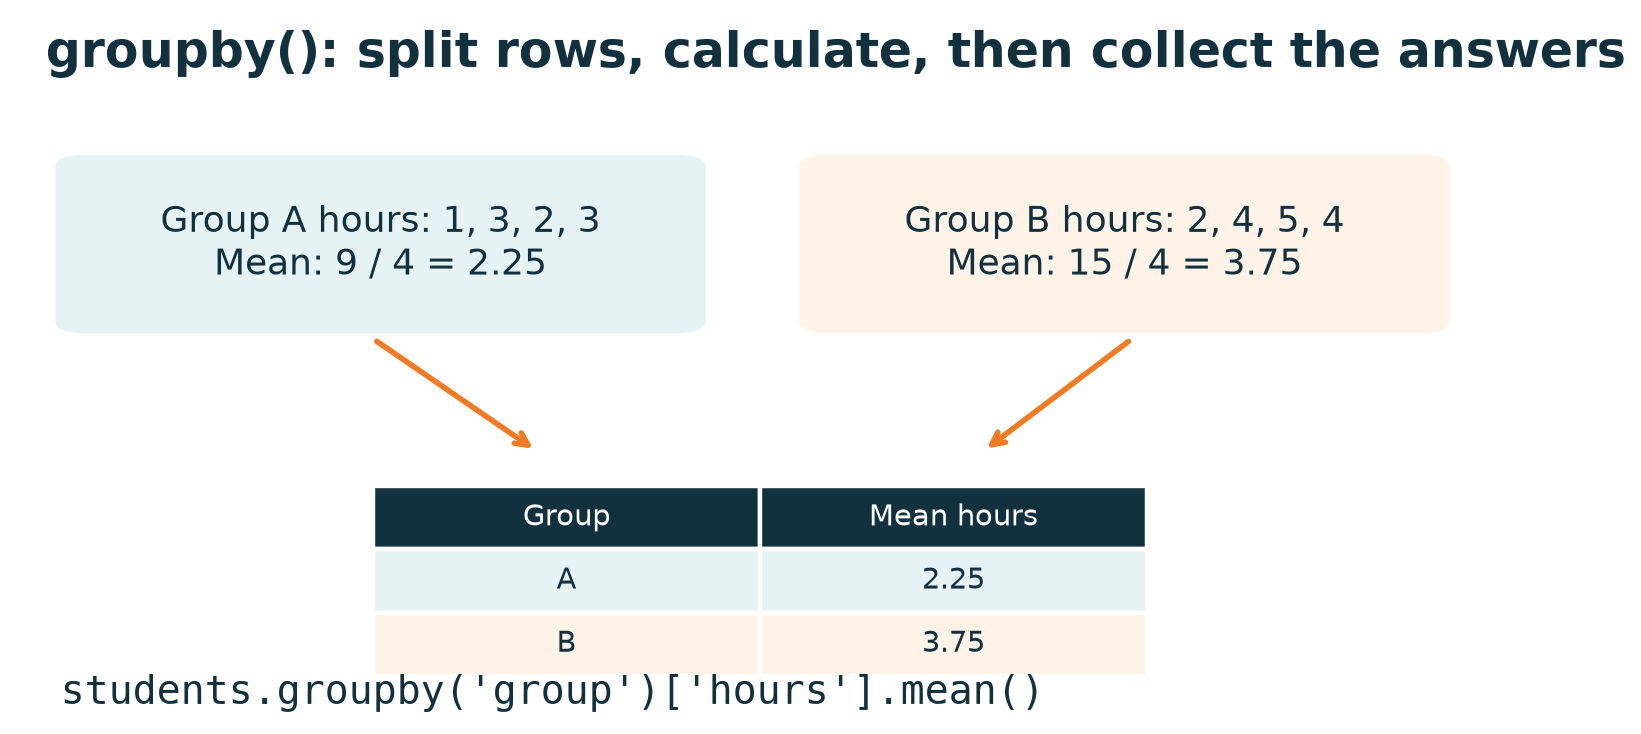

Rows are split by group. Only hours are selected. mean calculates one answer for each group.

In [57]:
grouped_students = students.groupby('group')  # Split rows by their group label.

In [58]:
group_hours = grouped_students['hours']  # Choose only the hours from each group.

In [59]:
group_hours.mean()  # Calculate one mean for each group: A and B.

group
A    2.25
B    3.75
Name: hours, dtype: float64

In [60]:
students.groupby('group')['score'].mean()  # Uses known scores only.

group
A    54.00
B    74.25
Name: score, dtype: float64

`agg()` applies more than one summary function. Below, `count` counts known scores. Group A has one missing score, so its count is smaller.

In [61]:
students.groupby('group')['score'].agg(['count', 'mean', 'min', 'max'])

,count,mean,min,max
group,,,,
A,3,54.00,45.0,65.0
B,4,74.25,55.0,90.0


## 17. Renaming and removing columns

`rename(columns=...)` changes column labels in the returned table. `drop(columns=...)` removes chosen columns from the returned table. Use these to keep names clear and include only what an analysis needs.

In [62]:
students.rename(columns={'hours': 'study_hours'}).head(2)

,student_id,name,group,study_hours,practice,score,study_minutes,score_filled
0,101,Asha,A,1,2,45.0,60,45.0
1,102,Bilal,B,2,4,55.0,120,55.0


In [63]:
students.drop(columns=['study_minutes']).head(2)

,student_id,name,group,hours,practice,score,score_filled
0,101,Asha,A,1,2,45.0,45.0
1,102,Bilal,B,2,4,55.0,55.0


## 18. Combining tables with merge()

A **merge** combines related records using a shared key. We have one small table giving a room for each group. We join that room to each student using the `group` key.

`how="left"` keeps all rows from the student table. Our room table has one row per group, so the merge adds information without multiplying student rows.

In [64]:
rooms = pd.DataFrame({'group': ['A', 'B'], 'room': ['Room 1', 'Room 2']})

In [65]:
rooms

,group,room
0,A,Room 1
1,B,Room 2


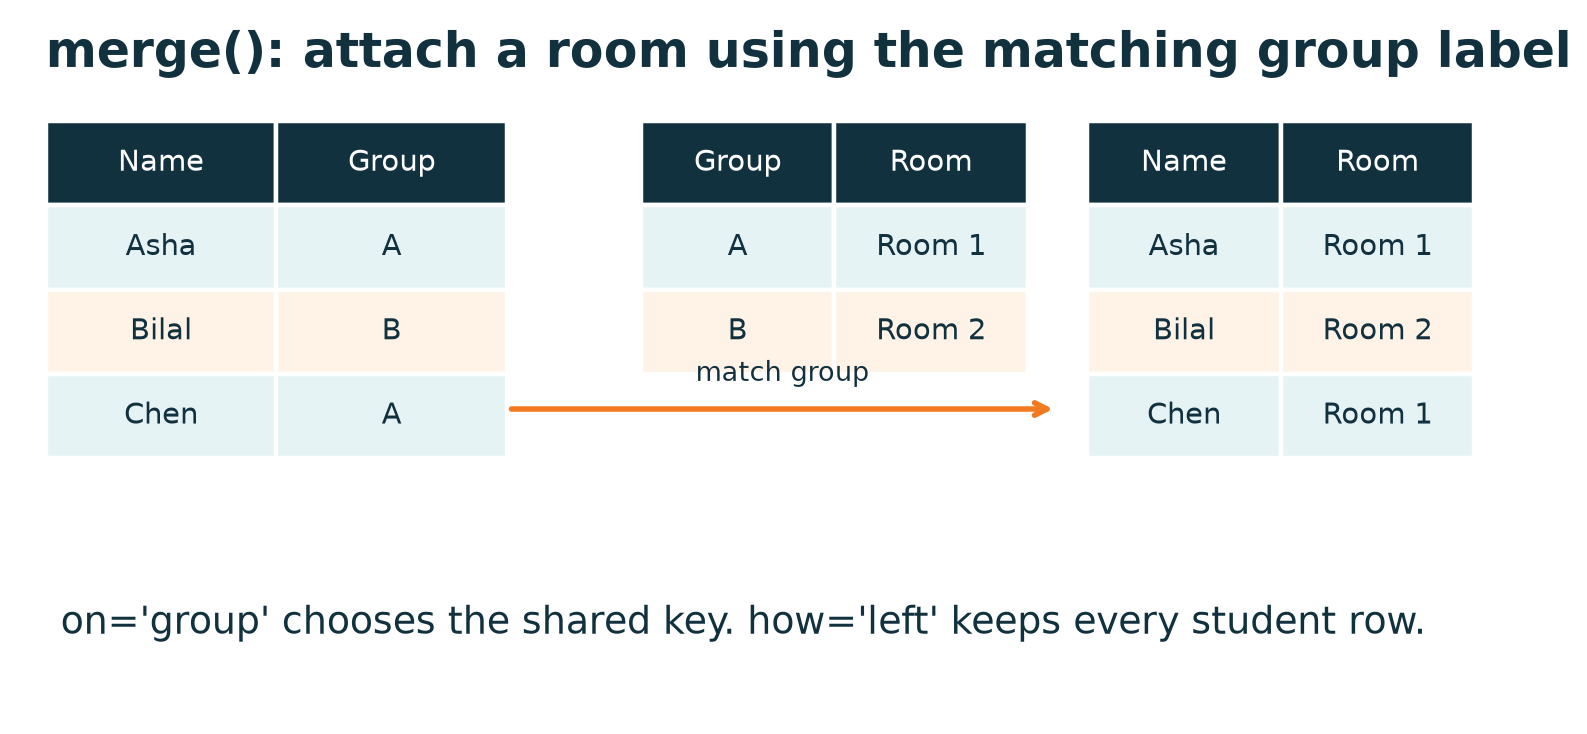

Each student finds the room with the same group label. A left join keeps the student even if no room matches.

In [66]:
# merge() attaches a room where the group labels match.
# how='left' keeps every row from students.
students_with_rooms = students.merge(rooms, on='group', how='left')

In [67]:
students_with_rooms[['name', 'group', 'room']]  # Show only the useful columns.

,name,group,room
0,Asha,A,Room 1
1,Bilal,B,Room 2
2,Chen,A,Room 1
3,Diya,B,Room 2
4,Eshan,A,Room 1
5,Fatima,B,Room 2
6,Gita,A,Room 1
7,Hari,B,Room 2


## 19. CSV files: saving and reading

A **CSV file** stores a table as text, with values separated by commas. `to_csv()` saves a DataFrame, and `read_csv()` reads it.

`index=False` avoids writing the row index as an extra column. This notebook creates its CSV before reading it, so no outside dataset is needed.

In [68]:
students.to_csv('student_study.csv', index=False)

In [69]:
loaded = pd.read_csv('student_study.csv')

In [70]:
loaded.head(3)

,student_id,name,group,hours,practice,score,study_minutes,score_filled
0,101,Asha,A,1,2,45.0,60,45.0
1,102,Bilal,B,2,4,55.0,120,55.0
2,103,Chen,A,3,5,65.0,180,65.0


## 20. Preparing a small table for AI

A **feature** is an input value a model can use. A **target** is the answer we want a model to learn to predict. In a later lesson, hours and practice could be features, and score could be the target.

Here we select known scores only. If we fill missing features in an ML project, we must learn the fill values from training data only. That keeps information from the test data out of training.

In [71]:
known_scores = students.dropna(subset=['score'])

In [72]:
features = known_scores[['hours', 'practice']]

In [73]:
target = known_scores['score']

In [74]:
features.head(3)

,hours,practice
0,1,2
1,2,4
2,3,5


In [75]:
features.to_numpy()  # Convert the two feature columns into a NumPy array.

array([[1, 2],
       [2, 4],
       [3, 5],
       [4, 7],
       [2, 3],
       [5, 8],
       [4, 6]])

## 21. Practice

1. Select name and score for students with at least four study hours.
2. Count missing scores.
3. Find the mean practice count for each group.
4. Explain the difference between `loc` and `iloc` using student 102.

In [76]:
students.loc[students['hours'] >= 4, ['name', 'score']]

,name,score
3,Diya,78.0
5,Fatima,90.0
7,Hari,74.0


In [77]:
students['score'].isna().sum()

np.int64(1)

In [78]:
students.groupby('group')['practice'].mean()

group
A    4.00
B    6.25
Name: practice, dtype: float64